# Moving Sum (MOSUM) Change-Point Detection

In [1]:
import numpy as np
import matplotlib.pyplot as plt

**MOSUM Statistics** - https://www.jstatsoft.org/article/view/v097i08 paper I am reading for meeting 1
Our objective is to read both papers and ask questions about the procedure

***2.1 MOSUM statistic***
Consider $X_1,X_2,X_3,.....X_n$ drawn from the same mean. By LLN follows that 

### 2.1 MOSUM statistic

Consider observations $X_1, \dots, X_n$ drawn independently from a distribution with the same mean as an example. By the Law of Large Numbers, it follows that

$$
\frac{1}{G}\sum_{t=k+1}^{k+G} X_t - \frac{1}{G}\sum_{t=k-G+1}^{k} X_t \approx 0
$$

for a sufficiently large *summation bandwidth* $G > 0$. If, on the other hand, there is a change in the mean of height $d$ at time point $k$, then

$$
\frac{1}{G}\sum_{t=k+1}^{k+G} X_t - \frac{1}{G}\sum_{t=k-G+1}^{k} X_t \approx d.
$$

Based on this observation, the following MOSUM statistic provides a good tool for change-point detection:

Out test statistic is for our mosum is 
$$
T_G := \max_{1 \le k \le n} \frac{|T_G(k)|}{\widehat{\sigma}_k} \tag{1}
$$
and our mosum detector $T_G(k)$

$$
T_G(k) = \sqrt{\frac{G}{2}} \left( \frac{1}{G}\sum_{t=k+1}^{k+G} X_t - \frac{1}{G}\sum_{t=k-G+1}^{k} X_t \right), \qquad k = G, \dots, n-G.
$$

For the boundary points $k = 1, \dots, G-1$ a CUSUM-type **boundary extension** is used instead:

$$
T_G(k) = \sqrt{\frac{2G}{k(2G-k)}} \sum_{t=1}^{k} \left( \bar{X}_{(1,2G)} - X_t \right), \qquad k = 1, \dots, G-1,
$$

with $\bar{X}_{(1,2G)} := (2G)^{-1} \sum_{t=1}^{2G} X_t$, and similarly for $k = n-G+1, \dots, n$ using the last $2G$ observations.


As less power for edge cases, where 
with $\bar{X}_{(1,2G)} := (2G)^{-1} \sum_{t=1}^{2G} X_t$ and similarly for $k = n-G+1, \dots, n$.

where the values $X_t$ are equal to:
$$
X_t = f_t + e_t = \sum_{j=1}^{N+1} \mu_j \, \mathbb{I}\{k_{j-1} < t \le k_j\} + e_t, \qquad t = 1, \dots, n. 
$$

Coding these Detectors:
$$ (1)MOSUM $$ $$(2) Boundary Point MOSUM$$

In [9]:
def MOSUM(X, G):
    data = np.array(X, dtype=float)
    n = len(data)
    S = np.concatenate(([0.0], np.cumsum(data)))
    K = np.arange(G, n - G + 1)
    T = (S[K + G] - S[K] + S[K - G] - S[K]) * np.sqrt( 1/(2*G))
    return K, T




To derive a MOSUM-based test for changes in the mean. Indeed, for appropriate bandwidths $G = G(n)$ satisfying $G \to \infty$ as $n \to \infty$ while $G/n \to 0$ 
$$
a_G T_G - b_G \Longrightarrow \Gamma_2 \quad \text{under } H_0 : \text{No mean change},
$$

where $\Longrightarrow$ denotes convergence in distribution, $\Gamma_2$ is a Gumbel-distributed random variable with $\mathbb{P}(\Gamma_2 \le z) = \exp\bigl(-2\exp(-z)\bigr)$, and $a_G$ and $b_G$ are sequences of properly chosen scaling and shifting factors depending only on the sample size $n$ and the bandwidth $G$.  $H_0 : N = 0$ against the alternative $H_1 : N > 0$ when the MOSUM statistic $T_G$ from (1) exceeds the asymptotic critical value

$$
C_{n,G}(\alpha) := \frac{b_G + Q_{1-\alpha}(\Gamma_2)}{a_G}, 
$$

where $Q_{1-\alpha}(\Gamma_2)$ is the $(1-\alpha)$-quantile of the Gumbel distribution. The $p$-value corresponding to the test statistic $t$ is given by

$$
p_{n,G}(t) = 1 - \exp\bigl(-2\exp(b_G - a_G t)\bigr).
$$

---

Test statistic:

$$
\begin{aligned}
\frac{|T_G(k)|}{\widehat{\sigma}_k} &\ge C_{n,G}(\alpha) \quad \text{for } k = l, \dots, r, \quad \text{and} \\
\frac{|T_G(k)|}{\widehat{\sigma}_k} &< C_{n,G}(\alpha) \quad \text{for } k = l-1,\, r+1.
\end{aligned}
$$


$$
k^{\circ}_{(l,r)} = \operatorname*{arg\,max}_{l \le k \le r} \frac{|T_G(k)|}{\widehat{\sigma}_k} 
$$

The $\epsilon$ criterion:

We say that $0 \lt \varepsilon \lt \tfrac{1}{2}$. And say that $k^{\circ}_{(l,r)}$
will be accepted if and only if 
$r - l \ge \varepsilon G$. Where it is recommended  for epsilon to be 0.2, and useful if bandwidth is larger than 20.

**The $\eta$-criterion.** Fix $\eta \ge 0$. A time point $k^{\circ}$ is accepted as a change-point estimate if and only if it maximises the scaled MOSUM statistic over its own window of radius $\eta G$:

$$
k^{\circ} = \operatorname*{arg\,max}_{k^{\circ} - \eta G \,\le\, k \,\le\, k^{\circ} + \eta G} \frac{|T_G(k)|}{\widehat{\sigma}_k}.
$$

In other words, $k^{\circ}$ must be a local maximum within a neighbourhood of radius $\eta G$. Simulation studies suggest $\eta = 0.4$ as a sensible default when nothing is known about how far apart the changes are. Unlike the $\varepsilon$-criterion, it does not require the whole $\eta G$ window to lie above the critical value $C_{n,G}(\alpha)$. Only the local maximum itself needs to be significant. This makes it less conservative, which is especially helpful when the bandwidth $G$ is small

The 2 main issues being, if the window is small, it will have issues registering when a change has occured as if a change has occured near the boundary it will register it as insignificant even though clearly a change has occured. This causing to discard the value \\
Another issue is that when the changes are closely spread, neighbouring changes are less than $2G$ spread apart so fails to register a change has occured. The $\varepsilon$-criterion treats this as a single significant environment and keeps only its global maximum, so the remaining changes are missed

### 2.3 Variance estimation

**Global sample variance** (unsuitable when there are mean changes, because it over-estimates $\sigma^2$):
$$
\widehat{\sigma}^2 = \frac{1}{n-1}\sum_{t=1}^{n}\big(X_t - \bar{X}_n\big)^2
$$

**Local sample variance** on the stretch $X_l, \dots, X_r$:
$$
\widehat{\sigma}^2_{(l,r)} := \frac{1}{r-l+1}\sum_{t=l}^{r}\big(X_t - \bar{X}_{(l,r)}\big)^2,
\qquad
\bar{X}_{(l,r)} := \frac{1}{r-l+1}\sum_{t=l}^{r} X_t
$$

**Local variance estimators for the MOSUM detector**, combining the left window $(k-G+1, k)$ and the right window $(k+1, k+G)$:
$$
\widehat{\sigma}^2_k = \frac{1}{2}\Big(\widehat{\sigma}^2_{(k-G+1,k)} + \widehat{\sigma}^2_{(k+1,k+G)}\Big) \tag{10}
$$
$$
\widehat{\sigma}^2_k = \min\Big\{\widehat{\sigma}^2_{(k-G+1,k)},\, \widehat{\sigma}^2_{(k+1,k+G)}\Big\} \tag{11}
$$
$$
\widehat{\sigma}^2_k = \max\Big\{\widehat{\sigma}^2_{(k-G+1,k)},\, \widehat{\sigma}^2_{(k+1,k+G)}\Big\} \tag{12}
$$

- (10) Average: the neutral default.
- (11) Minimum: preferable when both the mean and the variance change at a change point.
- (12) Maximum: more robust, since it prevents spurious detections under time-varying variance (heteroscedasticity).

**Dependent errors.** Under weak dependence, replace $\widehat{\sigma}^2_k$ with an estimate of the long-run variance
$$
\tau^2 = \lim_{n\to\infty} \operatorname{Var}\big(\sqrt{n}\,\bar{e}_n\big),
\qquad
\bar{e}_n = \frac{1}{n}\sum_{t=1}^{n} e_t .


### 2.4 Choice of bandwidth


Small G, localises well - finds the changepoint and close to true one. And seperate cllose changes meaning there are 2 distrinct peaks.

Large G - finds small jumps due to the averaging process, but struggles to find changepoints that are close together e.g. 300 and 350 when g = 100. Closer than 2G 


### 2.5 Asymmetric bandwidths

Let $\mathbf{G} = (G_l, G_r)$ be a possibly asymmetric bandwidth ($G_l \ne G_r$). The asymmetric MOSUM detector is

$$
T_{\mathbf{G}}(k) = \sqrt{\frac{G_l \cdot G_r}{G_l + G_r}}\left(\frac{1}{G_r}\sum_{t=k+1}^{k+G_r} X_t - \frac{1}{G_l}\sum_{t=k-G_l+1}^{k} X_t\right), \qquad k = G_l, \dots, n - G_r. \tag{13}
$$

At the boundaries, a CUSUM extension similar to (3) is used:

$$
T_{\mathbf{G}}(k) := \sqrt{\frac{G_l + G_r}{k\,(G_l + G_r - k)}}\sum_{t=1}^{k}\Big(\bar{X}_{(1,\,G_l+G_r)} - X_t\Big), \qquad k = 1, \dots, G_l - 1, \tag{14}
$$

and analogously for $k = n - G_r + 1, \dots, n$.


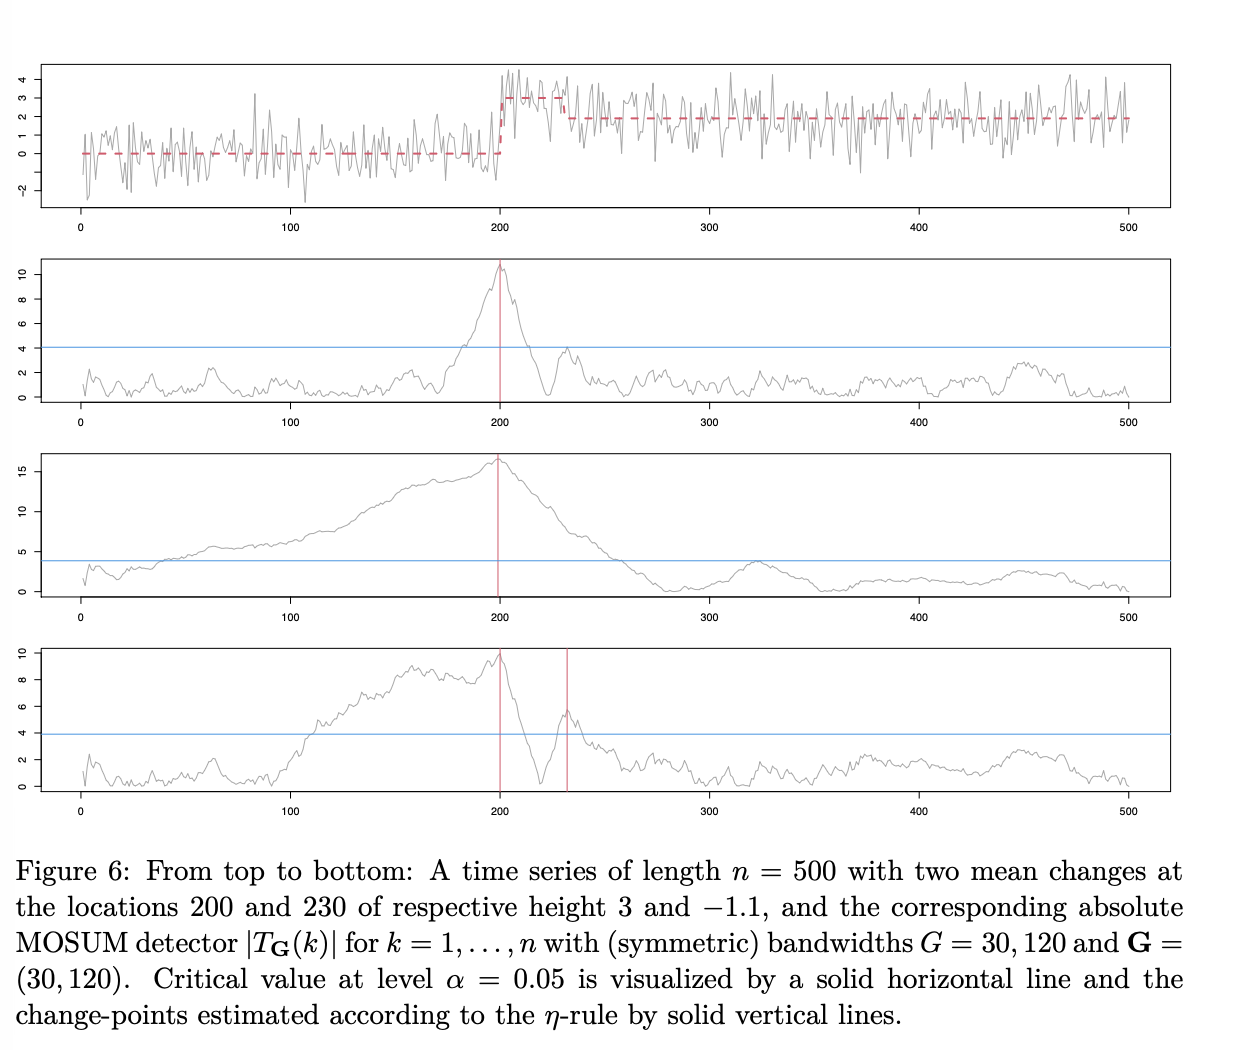

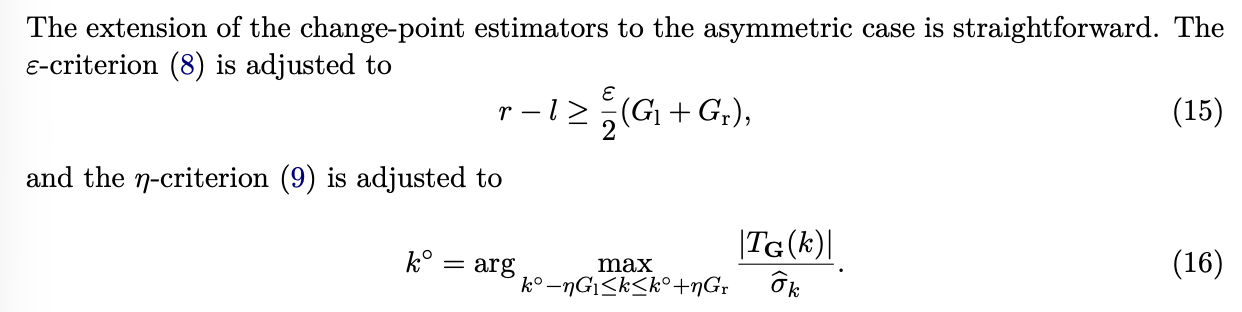

### Solving the bandwidth issue 2.6

This bandwidth Issue is solved with 2 different methods. 


With Multiscale MOSUM procedure with bottom-up merging and Multiscale MOSUM procedure with localised pruning.

going into more detail how these methods work. In summary they run several bandwidths so no change is missed. Then they are merged with overlapping detection into one final list.

### 1. Multiscale MOSUM with bottom-up merging:

1. Run MOSUM for each **symetric** bandwith $G$ and collect all detected change points.
2. Go through the candidates from **smallest to largest** bandwidth
3. Keep a candidate iff it is $\eta G$ away from every change point already accepted otherwise discard it.

**Idea:** Start with a smaller bandwidth and build up. This is because smaller bandwidths give the most precise locations, so trusted first. Larger bandwiths only add changes that the smaller ones have missed such as smaller jumps.

**Pros:** Simple and fast
**Cons** Works only with symmetric bandwidths, and false alarms from small bandwidths are accepted automatically
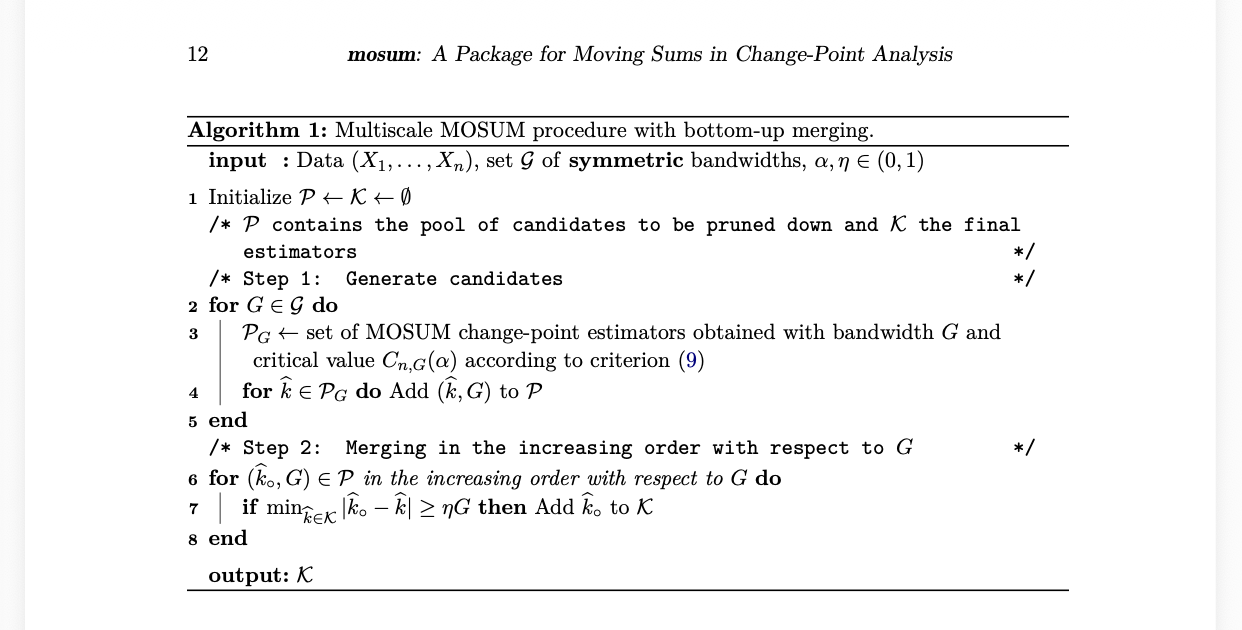
#### 2. Multiscale MOSUM with localised pruning

1. Run MOSUM for each of the bandwidths, can be symmetric or asymmetric and collect all detected change change points.
2. rank each change by its significance that being smallest p-value or largest jump first
3. Take the most significant candidate and gather the nearby candidates whose detection windows overlap with it, since they may describe the same change. 
4. among these, keep the combination that explains the data best without uncessery changes judged via the Schwarz Criterion
5. remove the resolved candidates and repeat until none remain

**Idea** the strongest evidence is trusted first, and then each local conflict is settled by which change point fits the data best

**pros**: works with assymetric bandwidth, less room for error and consistent in both number of change points and location

**cons** : more complex and alot slower

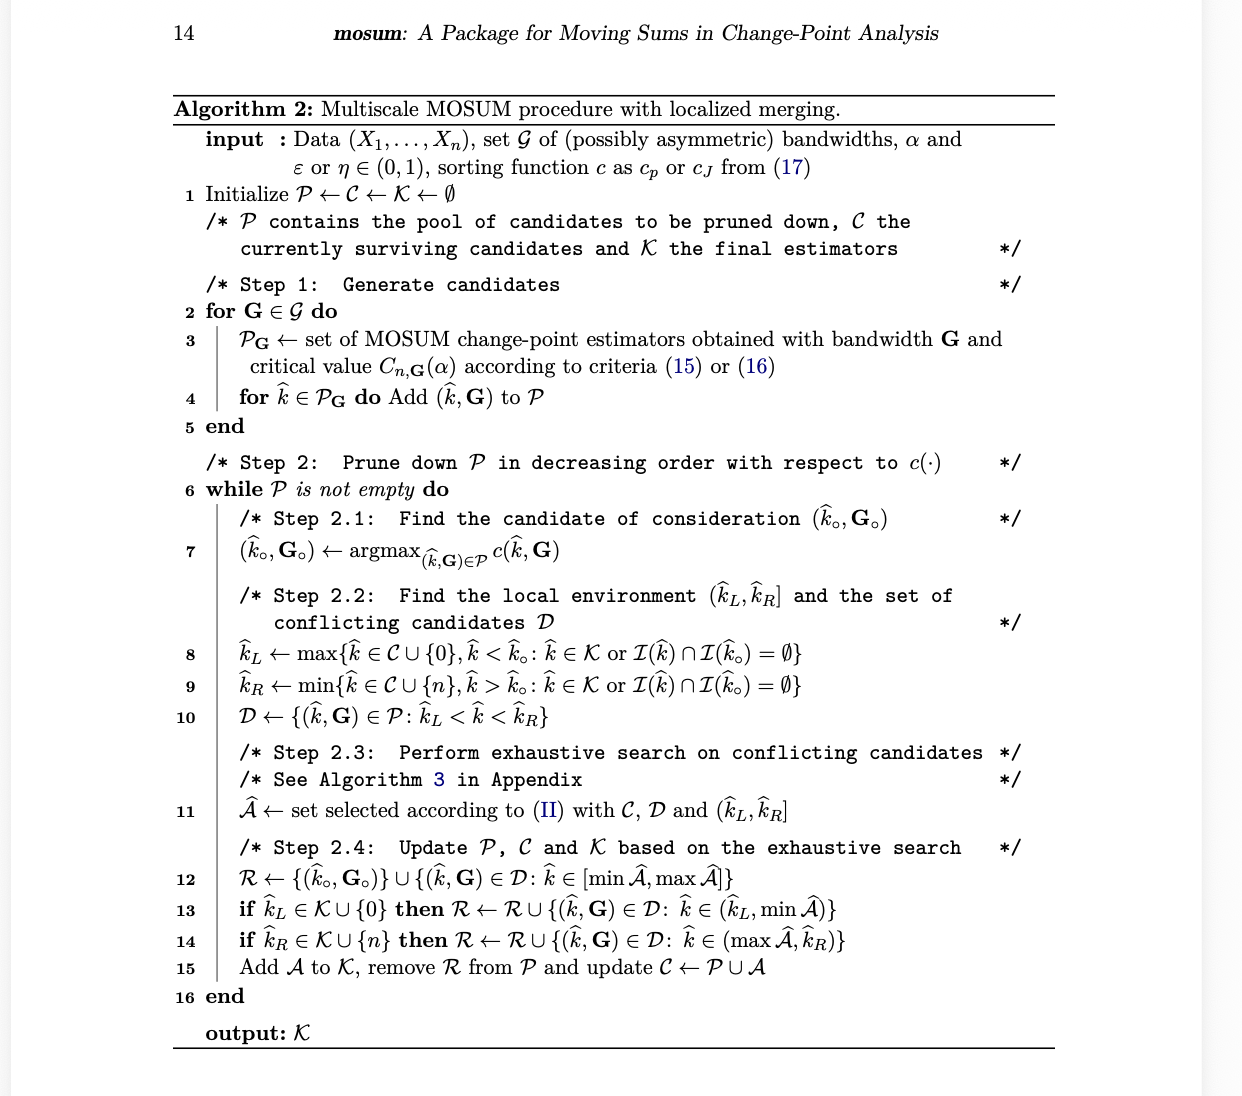

### 2.7 Bootstrapping confidence intervals

After finding out change points k1,....Kn. We can solve this through the method of bootstrapping. That if a change occured at 200, is the change truly at 200 or more at 195 or 208.

The boostrapping answers by resimulating the data many times and see how much the estimate moves. and measures the uncertainity of its locations.

1. It works by splitting the data into segments. This being between the estimated change points. Within each segment the mean is assumed flat.

2. Shuffle each segment, resample each segments observation with replacement. You get a new fake series with different noise.
 
3. Re-estimate each change point again. Run the MOSUM again on the fake series using the same badwidth and only look near the original estimate, with its detection window.

4. Repeat B 1000 times and measure the spread of our change points.


So summary, we have 2 segments [0,200] mean 0 , [200,400] mean 3. We then take the points in each segment and reshuffle them randomly in that segment, and repeat our change  point detection method again with same bandwidth , then continue and repeat B times to create intervals.

### Bootstrap confidence intervals: the simple version

**1. Segments** between the estimated change points $\widehat{k}_1, \dots, \widehat{k}_N$ (with $\widehat{k}_0 = 0$ and $\widehat{k}_{N+1} = n$):
$$
\mathcal{I}_j = \{\widehat{k}_{j-1}+1, \dots, \widehat{k}_j\}
$$

**2. Resample** within each segment, with replacement:
$$
X^*_t \sim \text{Uniform}\{X_s : s \in \mathcal{I}_j\}, \qquad t \in \mathcal{I}_j
$$

**3. Re-locate** each change near its original position:
$$
k^*_j = \operatorname*{arg\,max}_{\widehat{k}_j - G^l_j \,\lt\, k \,\le\, \widehat{k}_j + G^r_j} \big|T^*_{\mathbf{G}_j}(k)\big|
$$

**4. Repeat** $B$ times to get $k^*_{j,1}, \dots, k^*_{j,B}$.

**5. Confidence interval.** Let $M_j$ be the $(1-\alpha/2)$-quantile of the distances $|k^*_{j,b} - \widehat{k}_j|$. Then
$$
\widehat{k}_j \pm M_j
$$
is a $100(1-\alpha)\%$ confidence interval for the $j$-th change point.

### CH4 (Usage Examples)

### 4.3 Real data example: US ex-post real interest rate

**Data.** Quarterly US ex-post real interest rate, 1961 Q1 to 1986 Q3 ($n = 103$), a classic benchmark series (Garcia and Perron, 1996). The series shows signs of **time-varying variance** (heteroscedasticity).

**Method.** Multiscale MOSUM with **localised pruning** (Algorithm 2), using:
- the **max** local variance estimator (12), to avoid spurious detections caused by changing volatility;
- $\alpha = 0.1$ and the $\eta$-criterion with $\eta = 0.4$;
- the Schwarz Criterion penalty $p(n) = \log n$ with $\varrho = 1.01$;
- the default bandwidths.

**Result.** Two change points are detected at $\widehat{k}_1 = 47$ and $\widehat{k}_2 = 79$, corresponding to roughly **1972 Q3** and **1980 Q3**. The result is stable across a range of choices for $\alpha$, $\eta$ and $\varrho$, and it matches the breaks reported by Garcia and Perron (1996). Plausible economic drivers are the 1970s oil shock and the shift in US monetary policy around 1979 to 1980.

**Comparison with other methods.**
- **WBS, PELT and H-SMUCE** return exactly the same two change points.
- **TGUH, S3IB and FDRSeg** return additional, likely spurious, change points, possibly because they mistake changing variance for mean changes.
- **WBS, S3IB and cumSeg** require a maximum number of change points as input, and their output depends on it. The MOSUM procedure needs no such input.

**Confidence intervals.** The bootstrap uniform $90\%$ confidence intervals are considerably **narrower** than those produced by the competing stepR package, giving a more precise localisation of each change.

**Takeaway.** For real data with changing volatility, a conservative local variance estimate (the max estimator (12)) is key to avoiding false detections.

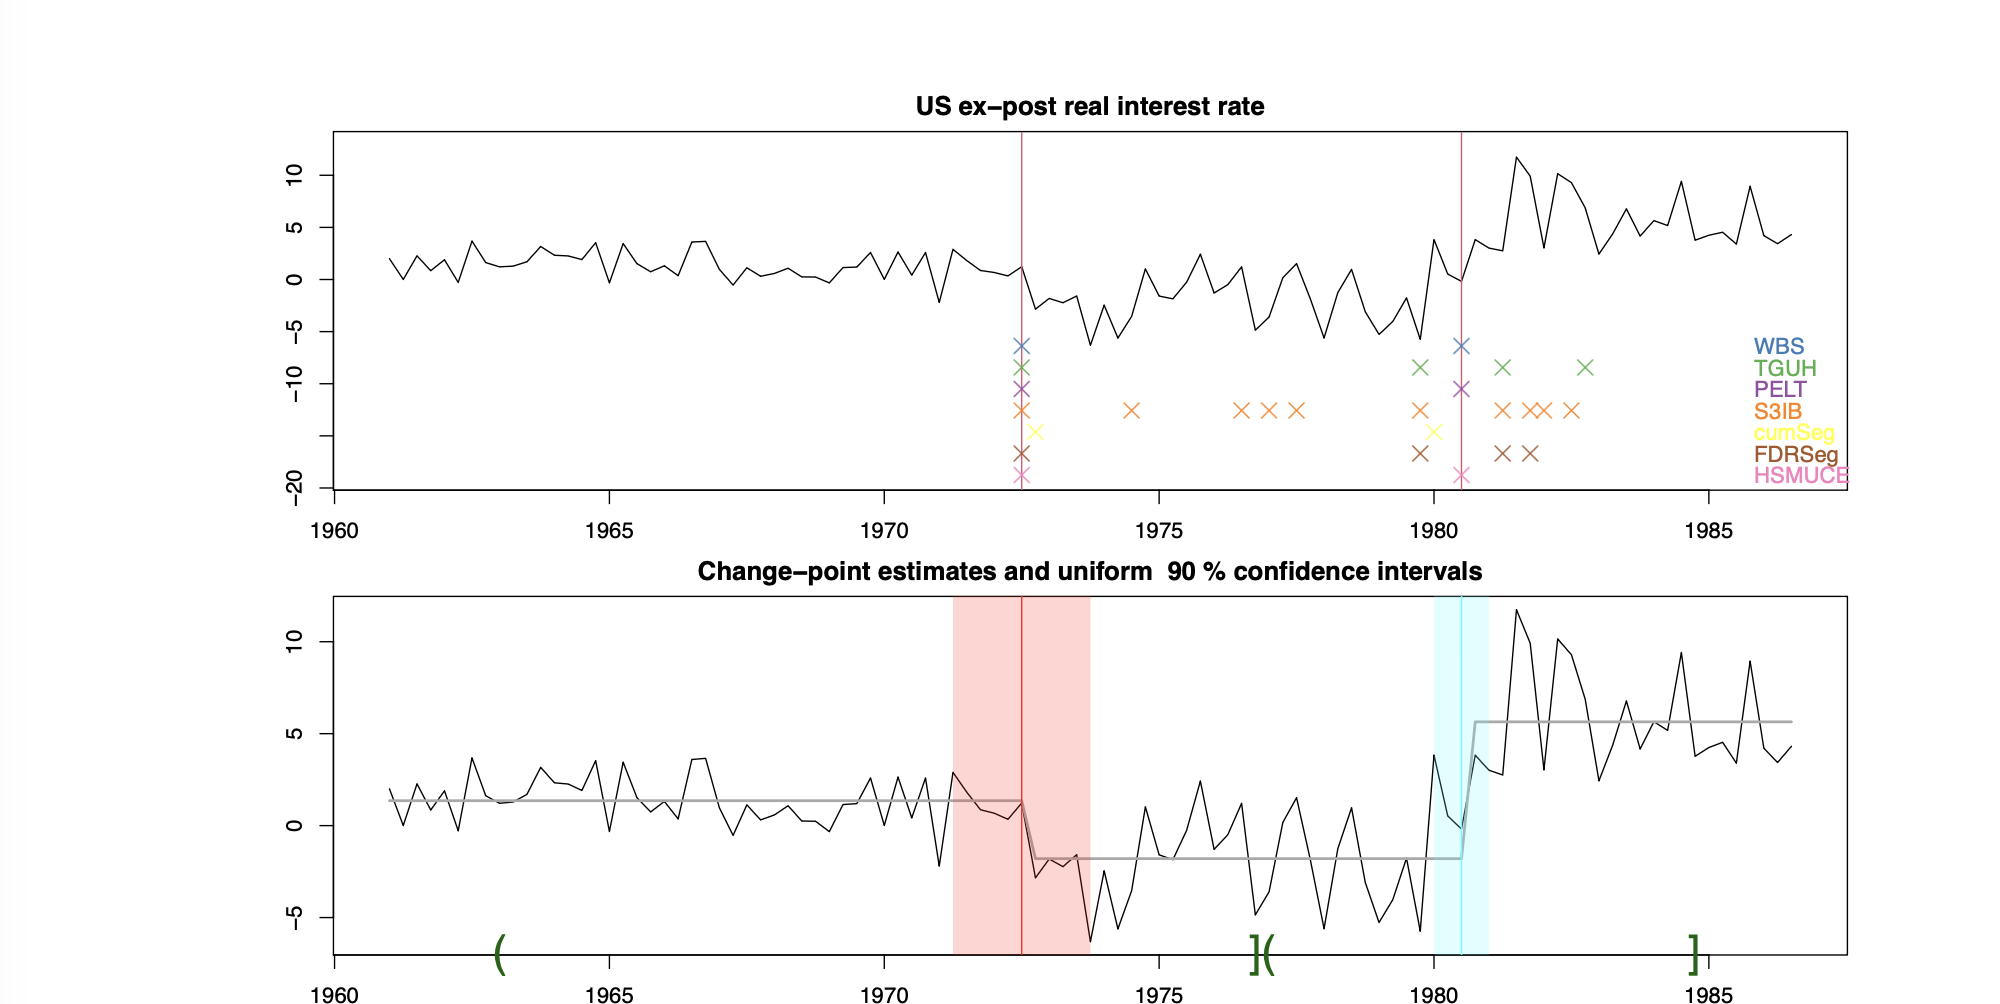